In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import quad, dblquad, trapezoid, simpson
from scipy.special import erf, spherical_jn, hyp1f1
from scipy.optimize import minimize

%matplotlib inline

plt.rcParams.update({
    "figure.figsize": (7.5, 5),
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "lines.linewidth": 1.8,
})

TWO_PI2 = 2.0 * np.pi**2


In [2]:
# ---- USER INPUT: change the field here and nowhere else --------------------

n_index = 4
R_f = 1.0

Pk = lambda k: k**n_index
W  = lambda k, R: np.exp(-0.5 * (k * R)**2)

# Numerical controls; these do not define the physical model.
K_MIN = 1e-6
K_MAX = 30.0 / R_f
N_GAUSS = 4000
# -----------------------------------------------------------------------------


In [3]:
TWO_PI2 = 2.0 * np.pi**2


class SmoothedGaussianField:
    '''Spectral moments and profile functions of a filtered Gaussian random field.'''

    def __init__(self, Pk, W, R_f, kmin=1e-6, kmax=None, nk=4000):
        self.Pk, self.W, self.R_f = Pk, W, R_f
        self.kmin = kmin
        self.kmax = kmax if kmax is not None else 30.0 / R_f   # Gaussian filter -> safe cutoff
        self.sigma0 = np.sqrt(self.moment2(0))
        self.sigma1 = np.sqrt(self.moment2(1))
        self.sigma2 = np.sqrt(self.moment2(2))
        self.gamma = self.sigma1**2 / (self.sigma0 * self.sigma2)
        self.Rstar = np.sqrt(3.0) * self.sigma1 / self.sigma2
        # fixed Gauss-Legendre nodes, for fast vectorised evaluation of psi & co.
        xg, wg = np.polynomial.legendre.leggauss(nk)
        self._k = 0.5 * (self.kmax - self.kmin) * xg + 0.5 * (self.kmax + self.kmin)
        self._w = 0.5 * (self.kmax - self.kmin) * wg
        self._base = (self._w * self.Pk(self._k) * self.W(self._k, self.R_f)**2
                      / (TWO_PI2 * self.sigma0**2))

    def moment2(self, j):
        '''Return sigma_j^2.'''
        f = lambda k: k**(2 + 2 * j) * self.Pk(k) * self.W(k, self.R_f)**2 / TWO_PI2
        val, _ = quad(f, self.kmin, self.kmax, limit=400)
        return val

    def profile_functions(self, u):
        '''Return psi, dpsi/du, Laplacian_u psi, and S at u=r/Rstar.'''
        u = np.atleast_1d(np.asarray(u, float))
        Y = np.outer(u, self._k * self.Rstar)                 # (n_u, n_k)
        j0, j1, j2 = (spherical_jn(m, Y) for m in (0, 1, 2))
        b, k, Rs = self._base, self._k, self.Rstar
        psi = j0 @ (b * k**2)
        dpsi = -Rs * (j1 @ (b * k**3))
        lap = -Rs**2 * (j0 @ (b * k**4))
        S = -(Rs**2 / 3.0) * (j2 @ (b * k**4))
        return psi, dpsi, lap, S

    def psi(self, u):
        return self.profile_functions(u)[0]


field = SmoothedGaussianField(Pk, W, R_f, K_MIN, K_MAX, N_GAUSS)
gamma = field.gamma
R_star = field.Rstar

print(f"  sigma_0 = {field.sigma0:.6e}")
print(f"  sigma_1 = {field.sigma1:.6e}")
print(f"  sigma_2 = {field.sigma2:.6e}")
print(f"  gamma   = {field.gamma:.6f}        [= sigma_1^2/(sigma_0 sigma_2)]")
print(f"  R_*     = {field.Rstar:.6f}        [= sqrt(3) sigma_1/sigma_2]  (same units as R_f)")
print(f"  R_*/R_f = {field.Rstar/R_f:.6f}")

# --- analytic cross-check, valid for a pure power law + Gaussian filter -------
g_exact = np.sqrt((n_index + 3) / (n_index + 5))           # BBKS eq. (E3)
Rs_exact = R_f * np.sqrt(6.0 / (n_index + 5))              # = sqrt(3) sigma_1/sigma_2
print(f"\nanalytic check (power law + Gaussian):  gamma = {g_exact:.6f},  R_* = {Rs_exact:.6f}")

  sigma_0 = 2.901404e-01
  sigma_1 = 5.428030e-01
  sigma_2 = 1.151459e+00
  gamma   = 0.881917        [= sigma_1^2/(sigma_0 sigma_2)]
  R_*     = 0.816497        [= sqrt(3) sigma_1/sigma_2]  (same units as R_f)
  R_*/R_f = 0.816497

analytic check (power law + Gaussian):  gamma = 0.881917,  R_* = 0.816497


### Differential and cumulative number densities, eq. (4.3)

In [5]:
def differential_number_density(nu, gamma, R_star):
    """
    N_pk(nu): comoving differential number density of peaks per unit nu,
    eq. (4.3). nu may be a scalar or a numpy array.
    """
    nu = np.asarray(nu, dtype=float)
    w = gamma * nu
    prefactor = 1.0 / (2.0 * np.pi) ** 2 / R_star**3
    return prefactor * np.exp(-nu**2 / 2.0) * G(gamma, w)


def cumulative_number_density(nu, gamma, R_star, nu_upper=40.0):
    """
    n_pk(>nu): comoving number density of peaks with height above nu,
    obtained by integrating the differential density (eq. 4.3) from nu
    to nu_upper (effectively infinity - the integrand is already
    negligible well before nu ~ 40 for any reasonable gamma).

    nu may be a scalar or a numpy array; returns the same shape.
    """
    nu = np.asarray(nu, dtype=float)
    scalar_input = nu.ndim == 0

    def integrand(x):
        return differential_number_density(x, gamma, R_star)

    flat = np.atleast_1d(nu)
    result = np.empty_like(flat)
    for i, nu_i in enumerate(flat):
        upper = max(nu_upper, nu_i + 10.0)  # keep upper limit safely above nu_i
        val, _ = quad(integrand, nu_i, upper, limit=200)
        result[i] = val

    return result.item() if scalar_input else result

### Exact $G(\gamma, w)$ from Appendix A (eq. A19)

The fitting formula (4.4)–(4.5) is only calibrated to be accurate for $0.3 \le \gamma \le 0.7$. To check it (and to get the true peak density outside that range), we can instead evaluate $G$ exactly via its defining integral, eq. (A19):

$$G(\gamma, x_*) = \int_0^\infty dx\, f(x)\, \frac{\exp\!\big[-(x-x_*)^2/2(1-\gamma^2)\big]}{\sqrt{2\pi(1-\gamma^2)}}$$

where $x = (\lambda_1+\lambda_2+\lambda_3)/\sigma_2$ is the (normalized) trace of the curvature tensor, restricted to $x\ge 0$ since all eigenvalues are non-negative at a maximum, and $f(x)$ is given in closed form by eq. (A15):

$$f(x) = \frac{x^3-3x}{2}\left[\mathrm{erf}\!\left(\sqrt{\tfrac{5}{2}}\,x\right) + \mathrm{erf}\!\left(\sqrt{\tfrac{5}{2}}\,\frac{x}{2}\right)\right] + \sqrt{\frac{2}{5\pi}}\left[\left(\frac{31x^2}{4}+\frac{8}{5}\right)e^{-5x^2/8} + \left(\frac{x^2}{2}-\frac{8}{5}\right)e^{-5x^2/2}\right]$$

$f(x)$ satisfies $f(x)\to x^3-3x$ as $x\to\infty$ (the spherical-peak limit) and $f(x)\sim x^8$ as $x\to 0$ (the "remarkable cancellation to eighth order" BBKS mention below eq. A16). We use this exact $f$ and $G$ below, alongside the fitted versions already defined above, so the two can be compared directly.

The same exact \(f(x)\) will also be reused for the peak-curvature distribution in §3.


In [6]:
from scipy.special import erf

def f_exact(x):
    """Exact f(x), eq. (A15). Defined for x >= 0 (sum of maximum's curvature eigenvalues / sigma2)."""
    x = np.asarray(x, dtype=float)
    term1 = 0.5 * (x**3 - 3*x) * (erf(np.sqrt(5/2)*x) + erf(np.sqrt(5/2)*x/2))
    term2 = np.sqrt(2/(5*np.pi)) * ((31*x**2/4 + 8/5)*np.exp(-5*x**2/8) + (x**2/2 - 8/5)*np.exp(-5*x**2/2))
    return term1 + term2

def f_bbks(x):
    '''BBKS eq. (A15). The small-x series (A16) is used below x = 0.2, where the
    closed form suffers from catastrophic cancellation.'''
    x = np.asarray(x, float)
    out = np.empty_like(x)
    sm = x < 0.2
    xs, xb = x[sm], x[~sm]
    out[sm] = (3**5 * 5**1.5 / (7 * 2**11 * np.sqrt(2 * np.pi))) * xs**8 * (1 - 5 * xs**2 / 8)
    out[~sm] = ((xb**3 - 3 * xb) * (erf(np.sqrt(2.5) * xb) + erf(np.sqrt(2.5) * xb / 2)) / 2
                + np.sqrt(2 / (5 * np.pi)) * ((31 * xb**2 / 4 + 8 / 5) * np.exp(-5 * xb**2 / 8)
                                              + (xb**2 / 2 - 8 / 5) * np.exp(-5 * xb**2 / 2)))
    return out


def G_exact(gamma, w, x_upper=60.0):
    """
    Exact G(gamma, w), eq. (A19), by numerically integrating f_exact(x) against
    the Gaussian kernel over x in [0, x_upper]. x_upper is pushed out further
    than w automatically so the (Gaussian-suppressed) tail is always captured.
    """
    sigma = np.sqrt(1.0 - gamma**2)

    def integrand(x):
        return f_exact(x) * np.exp(-(x - w)**2 / (2*sigma**2)) / (np.sqrt(2*np.pi)*sigma)

    upper = max(x_upper, w + 10*sigma + 10.0)
    val, _ = quad(integrand, 0.0, upper, limit=300)
    return val


def exact_differential_number_density(nu, gamma, R_star):
    """N_pk(nu) using the exact G (eq. A19) instead of the fitting formula (eq. 4.4)."""
    nu = np.asarray(nu, dtype=float)
    prefactor = 1.0 / (2.0 * np.pi) ** 2 / R_star**3

    flat = np.atleast_1d(nu)
    result = np.empty_like(flat, dtype=float)
    for i, nu_i in enumerate(flat):
        w = gamma * nu_i
        result[i] = prefactor * np.exp(-nu_i**2 / 2.0) * G_exact(gamma, w)
    return result.item() if nu.ndim == 0 else result


def exact_cumulative_number_density(nu, gamma, R_star, nu_upper=40.0):
    """n_pk(>nu) obtained by integrating the exact differential density."""
    nu = np.asarray(nu, dtype=float)
    scalar_input = nu.ndim == 0

    def integrand(x):
        return exact_differential_number_density(x, gamma, R_star)

    flat = np.atleast_1d(nu)
    result = np.empty_like(flat, dtype=float)
    for i, nu_i in enumerate(flat):
        upper = max(nu_upper, nu_i + 10.0)
        val, _ = quad(integrand, nu_i, upper, limit=100)
        result[i] = val

    return result.item() if scalar_input else result

In [10]:
import csv
import scipy.stats as stats


def read_u_common(path):
    """Read the shared u grid from the first nonempty row."""
    with open(path, newline="") as f:
        reader = csv.reader(f)
        for row in reader:
            if row:
                return np.array(row, dtype=float)
    raise ValueError("CSV file is empty.")


def iter_profiles_csv(path):
    """Yield one profile y at a time (u is stored in the first row)."""
    with open(path, newline="") as f:
        reader = csv.reader(f)

        # Skip the first nonempty row (the u grid)
        for row in reader:
            if row:
                break

        # Stream the remaining rows one by one
        for row in reader:
            if row:
                yield np.array(row, dtype=float)

In [11]:
# extract number density of peaks

csv_path_ga = "peaks_0.csv"
csv_path_ng1 = "peaks_2.csv"
csv_path_ng2 = "peaks_-2.csv"

nu = np.linspace(2.5, 6.0, 50)
dnu = nu[1] - nu[0]

# Common grid, read once
u_common = read_u_common(csv_path_ga)

number_density_ga = np.zeros_like(nu)

# 1. Extract selected profiles
for y in iter_profiles_csv(csv_path_ga):
    
    # Find the index of the current peak in the nu array
    i_nu = None
    for i, nu_val in enumerate(nu):
        if nu_val - dnu/2 <= y[0] < nu_val + dnu/2:
            i_nu = i
            break

    number_density_ga[i_nu] += 1 if i_nu is not None else 0

u_common = read_u_common(csv_path_ng1)

number_density_ng1 = np.zeros_like(nu)

# 1. Extract selected profiles
for y in iter_profiles_csv(csv_path_ng1):
    
    # Find the index of the current peak in the nu array
    i_nu = None
    for i, nu_val in enumerate(nu):
        if nu_val - dnu/2 <= y[0] < nu_val + dnu/2:
            i_nu = i
            break

    number_density_ng1[i_nu] += 1 if i_nu is not None else 0

u_common = read_u_common(csv_path_ng2)

number_density_ng2 = np.zeros_like(nu)

# 1. Extract selected profiles
for y in iter_profiles_csv(csv_path_ng2):
    
    # Find the index of the current peak in the nu array
    i_nu = None
    for i, nu_val in enumerate(nu):
        if nu_val - dnu/2 <= y[0] < nu_val + dnu/2:
            i_nu = i
            break

    number_density_ng2[i_nu] += 1 if i_nu is not None else 0

L = 40
N_rea = 5000
gamma_file = 0.77459667
Rs_file = 1.0954451  
number_density_ga /= 6 # avoid overcounting due to the profile extraction (six proifiles per peak)
number_density_ga /= dnu # Normalize by the bin width
number_density_ga /= L**3  # Divide by the volume and the number of realizations
number_density_ga /= N_rea  # Divide by the number of realizations

number_density_ng1 /= 6 * dnu * L**3 * N_rea  # avoid overcounting due to the profile extraction (six proifiles per peak)
number_density_ng2 /= 6 * dnu * L**3 * N_rea  # avoid overcounting due to the profile extraction (six proifiles per peak)


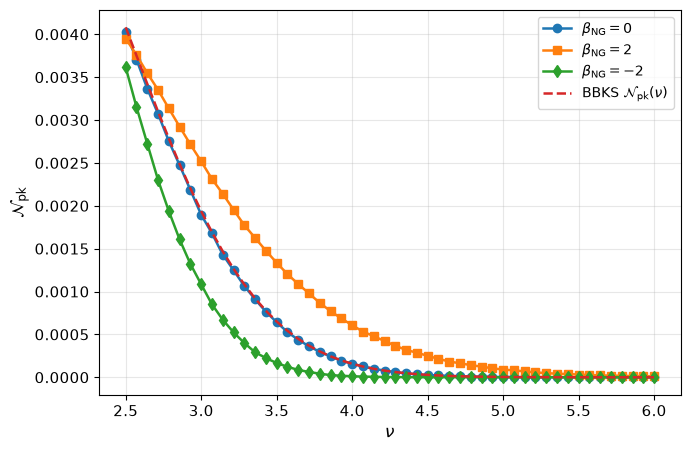

In [12]:
plt.plot(nu, number_density_ga, "o-", label=r"$\beta_{\rm NG} = 0$")
plt.plot(nu, number_density_ng1, "s-", label=r"$\beta_{\rm NG} = 2$")
plt.plot(nu, number_density_ng2, "d-", label=r"$\beta_{\rm NG} = -2$")
plt.plot(nu, exact_differential_number_density(nu, gamma_file, Rs_file), "--", label=r"BBKS $\mathcal{N}_{\rm pk}(\nu)$")
plt.xlabel(r"$\nu$", fontsize=12)
plt.ylabel(r"$\mathcal{N}_{\rm pk}$", fontsize=12)
plt.legend(fontsize=10)
plt.show()

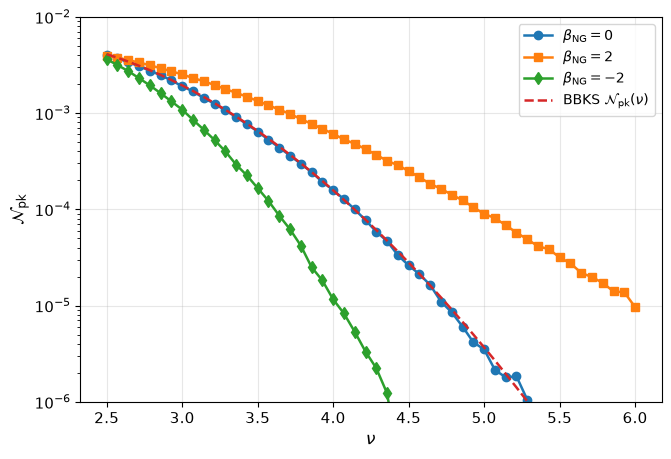

In [13]:
plt.plot(nu, number_density_ga, "o-", label=r"$\beta_{\rm NG} = 0$")
plt.plot(nu, number_density_ng1, "s-", label=r"$\beta_{\rm NG} = 2$")
plt.plot(nu, number_density_ng2, "d-", label=r"$\beta_{\rm NG} = -2$")
plt.plot(nu, exact_differential_number_density(nu, gamma_file, Rs_file), "--", label=r"BBKS $\mathcal{N}_{\rm pk}(\nu)$")
plt.xlabel(r"$\nu$", fontsize=12)
plt.ylabel(r"$\mathcal{N}_{\rm pk}$", fontsize=12)
plt.yscale("log")
plt.ylim(1e-6, 1e-2)
plt.legend(fontsize=10)
plt.show()

### Expected number of peaks over a threshold from a single realization

In [14]:
NU_TEST = 2.4
BOX_SIZE = 20.0

expected_peaks = exact_cumulative_number_density(NU_TEST, gamma_file, Rs_file) * BOX_SIZE**3
print(f"n_pk(>nu={NU_TEST:g}) * L^3 = {expected_peaks:.6g}  for L={BOX_SIZE:g}")


n_pk(>nu=2.4) * L^3 = 21.9427  for L=20
